# Tahap 1 — Audit Data ACLED

Tujuan: memeriksa kualitas dan isi data ACLED sebelum diolah, sebagai dasar
dua keputusan Tahap 1:

1. Apakah *Riots* ikut dihitung bersama *Protests*?
2. Berapa ambang `geo_precision` yang dipakai?

Notebook ini hanya membaca data mentah (tidak mengubahnya) dan menyimpan
tabel ringkasan ke `results/tables/` serta grafik ke `results/figures/`.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

pd.set_option("display.max_columns", 30)

# Root repository = folder induk yang berisi pyproject.toml
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").is_file())
ACLED_DIR = ROOT / "data" / "raw" / "acled"
TABLES = ROOT / "results" / "tables"
FIGURES = ROOT / "results" / "figures"
TABLES.mkdir(parents=True, exist_ok=True)
FIGURES.mkdir(parents=True, exist_ok=True)

files = sorted(ACLED_DIR.glob("*.csv"))
if len(files) != 1:
    raise FileNotFoundError(
        f"Harus ada tepat satu CSV ACLED di {ACLED_DIR}, ditemukan {len(files)}. "
        "Unduh data ACLED Indonesia dari https://acleddata.com dan simpan di folder tersebut."
    )
ACLED_FILE = files[0]
print("File:", ACLED_FILE.name)

File: ACLED Data_2026-11-16_event_date_from_2024-10-20_event_date_to_2025-11-16.csv


In [2]:
acled = pd.read_csv(ACLED_FILE, encoding="utf-8", low_memory=False)
acled["event_date"] = pd.to_datetime(acled["event_date"], errors="coerce")
print(f"{acled.shape[0]:,} baris x {acled.shape[1]} kolom")
print(list(acled.columns))

4,978 baris x 31 kolom
['event_id_cnty', 'event_date', 'year', 'time_precision', 'disorder_type', 'event_type', 'sub_event_type', 'actor1', 'assoc_actor_1', 'inter1', 'actor2', 'assoc_actor_2', 'inter2', 'interaction', 'civilian_targeting', 'iso', 'region', 'country', 'admin1', 'admin2', 'admin3', 'location', 'latitude', 'longitude', 'geo_precision', 'source', 'source_scale', 'notes', 'fatalities', 'tags', 'timestamp']


## 1. Identitas dan duplikasi

In [3]:
print("Negara unik:", acled["country"].unique().tolist())
print("Duplikasi event_id_cnty:", acled["event_id_cnty"].duplicated().sum())

# Kemungkinan kejadian ganda: tanggal, lokasi, dan sub-kategori yang sama persis
key = ["event_date", "latitude", "longitude", "sub_event_type"]
same = acled[acled.duplicated(key, keep=False)]
print(f"Baris dengan tanggal+koordinat+sub_event_type sama: {len(same)} "
      f"({same.groupby(key).ngroups} kelompok)")

Negara unik: ['Indonesia']
Duplikasi event_id_cnty: 0
Baris dengan tanggal+koordinat+sub_event_type sama: 520 (237 kelompok)


Catatan: kejadian dengan tanggal dan lokasi sama belum tentu duplikat — ACLED
bisa mencatat beberapa aksi berbeda (aktor/tuntutan berbeda) di tempat yang
sama. Angka ini hanya sebagai informasi, tidak otomatis dihapus.

## 2. Kategori kejadian

In [4]:
PROVISIONAL = {"Protests": 4415, "Riots": 563, "total": 4978}

by_type = acled["event_type"].value_counts()
print(by_type.to_string())
print(f"Total: {len(acled)} (angka awal: {PROVISIONAL['total']})")
for k in ("Protests", "Riots"):
    print(f"  {k}: {by_type.get(k, 0)} (angka awal: {PROVISIONAL[k]})")

event_type
Protests    4415
Riots        563
Total: 4978 (angka awal: 4978)
  Protests: 4415 (angka awal: 4415)
  Riots: 563 (angka awal: 563)


In [5]:
by_sub = (
    acled.groupby(["disorder_type", "event_type", "sub_event_type"])
    .size().rename("n").reset_index()
)
by_sub["pct"] = (by_sub["n"] / len(acled) * 100).round(2)
by_sub.to_csv(TABLES / "01_event_categories.csv", index=False)
by_sub

,disorder_type,event_type,sub_event_type,n,pct
0,Demonstrations,Protests,Peaceful protest,4324,86.86
1,Demonstrations,Protests,Protest with intervention,89,1.79
2,Demonstrations,Riots,Violent demonstration,246,4.94
3,Political violence,Riots,Mob violence,317,6.37
4,Political violence; Demonstrations,Protests,Excessive force against protesters,2,0.04


## 3. Waktu

In [6]:
print("Tanggal tidak terbaca:", acled["event_date"].isna().sum())
print("Rentang:", acled["event_date"].min().date(), "s.d.", acled["event_date"].max().date())
print("\ntime_precision:")
print(acled["time_precision"].value_counts().sort_index().to_string())

Tanggal tidak terbaca: 0
Rentang: 2024-10-20 s.d. 2025-11-16

time_precision:
time_precision
1    4860
2     112
3       6


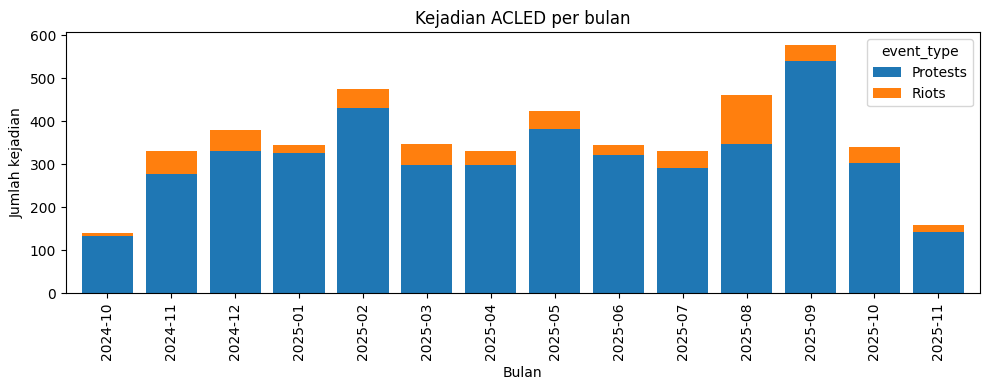

month,2024-10,2024-11,2024-12,2025-01,2025-02,2025-03,2025-04,2025-05,2025-06,2025-07,2025-08,2025-09,2025-10,2025-11
event_type,,,,,,,,,,,,,,
Protests,133,277,330,325,430,299,297,381,321,291,346,540,302,143
Riots,7,53,49,20,44,47,33,42,24,39,114,38,37,16


In [7]:
monthly = (
    acled.assign(month=acled["event_date"].dt.to_period("M"))
    .groupby(["month", "event_type"]).size().unstack(fill_value=0)
)
monthly.to_csv(TABLES / "01_monthly_counts.csv")

ax = monthly.plot(kind="bar", stacked=True, figsize=(10, 4), width=0.8)
ax.set_xlabel("Bulan")
ax.set_ylabel("Jumlah kejadian")
ax.set_title("Kejadian ACLED per bulan")
plt.tight_layout()
plt.savefig(FIGURES / "01_monthly_counts.png", dpi=150)
plt.show()
monthly.T

Catatan: bulan pertama (Okt 2024, mulai tgl 20) dan terakhir (Nov 2025, s.d.
tgl 16) hanya terhitung sebagian bulan.

## 4. Lokasi dan presisi lokasi

In [8]:
lat, lon = acled["latitude"], acled["longitude"]
print("Koordinat kosong:", (lat.isna() | lon.isna()).sum())

# Kotak batas kasar Indonesia (hanya pemeriksaan kasar, bukan batas resmi)
outside = ~(lat.between(-11.5, 6.5) & lon.between(94.5, 141.5))
print("Koordinat di luar kotak batas kasar Indonesia:", outside.sum())

Koordinat kosong: 0
Koordinat di luar kotak batas kasar Indonesia: 0


`geo_precision` menurut codebook ACLED (perlu dicek ulang di codebook resmi):
**1** = lokasi spesifik (kota/desa), **2** = sekitar lokasi atau bagian wilayah
yang lebih besar, **3** = hanya diketahui wilayah administratif yang lebih luas
(lokasi diwakili titik pusat wilayah).

In [9]:
geo = pd.crosstab(acled["event_type"], acled["geo_precision"], margins=True, margins_name="Total")
geo_pct = pd.crosstab(acled["event_type"], acled["geo_precision"], normalize="index").mul(100).round(2)
geo.to_csv(TABLES / "01_geo_precision.csv")
display(geo)
geo_pct

geo_precision,1,2,3,Total
event_type,,,,
Protests,4338,62,15,4415
Riots,546,17,0,563
Total,4884,79,15,4978


geo_precision,1,2,3
event_type,,,
Protests,98.26,1.40,0.34
Riots,96.98,3.02,0.00


## 5. Cakupan wilayah

In [10]:
print("Provinsi (admin1) unik:", acled["admin1"].nunique())
print("Kab/kota (admin2) unik:", acled["admin2"].nunique())
print("admin2 kosong:", acled["admin2"].isna().sum())

acled.loc[
    acled["admin2"].isna(),
    ["event_date", "event_type", "admin1", "location", "latitude", "longitude", "geo_precision"],
]

Provinsi (admin1) unik: 38
Kab/kota (admin2) unik: 405
admin2 kosong: 18


,event_date,event_type,admin1,location,latitude,longitude,geo_precision
36,2024-10-23,Protests,Jakarta,Jakarta - Unspecified,-6.2146,106.845,1
685,2024-12-15,Protests,Jakarta,Jakarta - Unspecified,-6.2146,106.845,1
737,2024-12-18,Protests,Jakarta,Jakarta - Unspecified,-6.2146,106.845,1
997,2025-01-14,Protests,Jakarta,Jakarta - Unspecified,-6.2146,106.845,1
1153,2025-01-26,Protests,Jakarta,Jakarta - Unspecified,-6.2146,106.845,1
1562,2025-02-21,Protests,Jakarta,Jakarta - Unspecified,-6.2146,106.845,1
1570,2025-02-21,Protests,Jakarta,Jakarta - Unspecified,-6.2146,106.845,1
1625,2025-02-26,Protests,Jakarta,Jakarta - Unspecified,-6.2146,106.845,1
1913,2025-03-23,Protests,Jakarta,Jakarta - Unspecified,-6.2146,106.845,1
2476,2025-05-07,Protests,Jakarta,Jakarta - Unspecified,-6.2146,106.845,1


In [11]:
by_admin2 = (
    acled.groupby(["admin1", "admin2"]).size().rename("n").reset_index()
    .sort_values("n", ascending=False, ignore_index=True)
)
by_admin2.to_csv(TABLES / "01_events_by_admin2.csv", index=False)

top10_share = by_admin2["n"].head(10).sum() / len(acled) * 100
print(f"10 kab/kota teratas menyumbang {top10_share:.1f}% kejadian")
print("Median kejadian per kab/kota (yang punya kejadian):", by_admin2["n"].median())
by_admin2.head(15)

10 kab/kota teratas menyumbang 24.9% kejadian
Median kejadian per kab/kota (yang punya kejadian): 6.0


,admin1,admin2,n
0,Jakarta,Central Jakarta,353
1,South Sulawesi,Makassar,138
2,Jakarta,South Jakarta,127
3,Papua,Jayapura,115
4,North Sumatra,Medan,103
5,West Java,Bandung,97
6,Central Java,Semarang,86
7,Southwest Papua,Sorong,86
8,East Java,Surabaya,69
9,Yogyakarta,Yogyakarta,68


In [12]:
by_admin1 = acled["admin1"].value_counts().rename_axis("admin1").reset_index(name="n")
by_admin1.to_csv(TABLES / "01_events_by_admin1.csv", index=False)
by_admin1

,admin1,n
0,Jakarta,571
1,West Java,453
2,Central Java,449
3,East Java,406
4,South Sulawesi,334
5,North Sumatra,222
6,Banten,162
7,Central Sulawesi,143
8,West Nusa Tenggara,137
9,Aceh,137


## 6. Nilai hilang

In [13]:
missing = acled.isna().sum().rename("n_missing").to_frame()
missing["pct"] = (missing["n_missing"] / len(acled) * 100).round(2)
missing = missing.sort_values("n_missing", ascending=False)
missing.to_csv(TABLES / "01_missing_values.csv")
missing[missing["n_missing"] > 0]

,n_missing,pct
civilian_targeting,4813,96.69
assoc_actor_2,4788,96.18
actor2,4428,88.95
inter2,4428,88.95
assoc_actor_1,1585,31.84
admin3,19,0.38
admin2,18,0.36


Kolom aktor kedua (`actor2`, `inter2`, dll.) dan `civilian_targeting` memang
wajar banyak kosong untuk aksi protes. Kolom yang penting untuk analisis
adalah tanggal, kategori, koordinat, `geo_precision`, dan `admin2`.

## 7. Apakah `admin2` bisa dipakai untuk menentukan kab/kota?

Banyak kabupaten dan kota di Indonesia bernama sama (mis. Kabupaten Bandung
dan Kota Bandung). Cek apakah ACLED membedakannya.

In [14]:
admin2_names = set(acled["admin2"].dropna())
for name in ["Bandung", "Bogor", "Bekasi", "Tangerang", "Semarang", "Malang", "Serang", "Jayapura", "Sorong"]:
    variants = sorted(n for n in admin2_names if n.startswith(name))
    print(f"{name:10s} -> {variants}")

Bandung    -> ['Bandung']
Bogor      -> ['Bogor']
Bekasi     -> ['Bekasi']
Tangerang  -> ['Tangerang']
Semarang   -> ['Semarang']
Malang     -> ['Malang']
Serang     -> ['Serang']
Jayapura   -> ['Jayapura']
Sorong     -> ['Sorong']


ACLED **tidak membedakan** kabupaten dan kota yang bernama sama — keduanya
tercatat dengan satu nama. Akibatnya:

- jumlah `admin2` unik (405) **lebih kecil** dari jumlah kab/kota sebenarnya
  yang punya kejadian;
- `admin2` **tidak bisa** dipakai untuk memetakan kejadian ke kab/kota.
  Pemetaan harus lewat **spatial join** koordinat ke poligon batas kab/kota
  (Tahap 4). 18 kejadian dengan `admin2` kosong ("Jakarta - Unspecified")
  juga akan terpetakan lewat koordinatnya.

## 8. Keputusan Tahap 1 dan penerapannya

| Keputusan | Pilihan | Alasan |
| --- | --- | --- |
| Kategori Y | *Protests* + *Violent demonstration* (semua kejadian `disorder_type` "Demonstrations") | *Mob violence* sebagian besar main hakim sendiri / bentrok antarkelompok, bukan aksi protes |
| `geo_precision` | Semua (1–3) | Presisi 3 hanya 0,3% dan berada di pusat kota; ambang ≤ 2 dapat dipakai sebagai uji ketahanan |

In [ ]:
INCLUDED_SUB_EVENTS = [
    "Peaceful protest",
    "Protest with intervention",
    "Excessive force against protesters",
    "Violent demonstration ",
]
MAX_GEO_PRECISION = 3   # semua presisi dipakai

protests = acled[
    acled["sub_event_type"].isin(INCLUDED_SUB_EVENTS)
    & (acled["geo_precision"] <= MAX_GEO_PRECISION)
].copy()

print(f"Kejadian terpilih: {len(protests):,} dari {len(acled):,}")
print(protests["sub_event_type"].value_counts().to_string())
print("Dibuang (Mob violence):", (acled["sub_event_type"] == "Mob violence").sum())

Kejadian terpilih: 4,661 dari 4,978
sub_event_type
Peaceful protest                      4324
Violent demonstration                  246
Protest with intervention               89
Excessive force against protesters       2
Dibuang (Mob violence): 317


In [16]:
# Simpan kolom yang diperlukan untuk Tahap 4 (folder data/ tidak di-commit)
INTERIM = ROOT / "data" / "interim"
INTERIM.mkdir(parents=True, exist_ok=True)
keep = ["event_id_cnty", "event_date", "event_type", "sub_event_type",
        "admin1", "admin2", "location", "latitude", "longitude", "geo_precision"]
protests[keep].to_csv(INTERIM / "acled_protests_selected.csv", index=False)
print("Disimpan:", (INTERIM / "acled_protests_selected.csv").relative_to(ROOT))

Disimpan: data\interim\acled_protests_selected.csv


## Ringkasan audit

| Aspek | Temuan |
| --- | --- |
| Jumlah kejadian | 4.978 (4.415 *Protests* + 563 *Riots*) — **cocok** dengan angka awal |
| Duplikasi ID | Tidak ada |
| Periode | 20 Okt 2024 – 16 Nov 2025, semua tanggal terbaca; bulan pertama & terakhir tidak penuh |
| Presisi waktu | 4.860 tanggal pasti, 112 tingkat minggu, 6 tingkat bulan — tidak masalah karena agregasi seluruh periode |
| Koordinat | Lengkap, semua di dalam wilayah Indonesia |
| `geo_precision` | 98,1% presisi 1; 79 presisi 2; 15 presisi 3 |
| `admin2` | 18 kosong (Jakarta); **tidak membedakan kabupaten vs kota bernama sama** → wajib spatial join |
| Sebaran | 38 provinsi; 10 `admin2` teratas = 24,9% kejadian; median 6 kejadian per `admin2` |
| Pola waktu | Lonjakan *Riots* Agustus 2025 (114) dan *Protests* September 2025 (540) |
| Kejadian lokasi-tanggal sama | 520 baris (237 kelompok) — dibiarkan, bisa aksi berbeda di tempat yang sama |

**Hasil Tahap 1:** 4.661 kejadian terpilih (4.415 *Protests* + 246 *Violent
demonstration*), disimpan di `data/interim/acled_protests_selected.csv`.

**Catatan untuk tahap berikutnya:**

- Tahap 4: pemetaan ke kab/kota lewat spatial join, bukan `admin2`.
- Uji ketahanan: ulangi analisis akhir dengan `geo_precision ≤ 2`.
- Definisi `geo_precision` di atas perlu dicocokkan dengan codebook ACLED resmi.